# 산불 탐지 프로젝트 · 다른 출처 시험 데이터 가공과 전처리 (D-Fire, DeepFire)

**역할** 두 데이터는 학습에 쓰지 않고 **시험에만** 쓴다. AI Hub로 학습한 모델이 나라·카메라·촬영 방식이 다른 사진에서도 통하는지,
특히 구름·안개·노을·밤 불빛 같은 헷갈리는 음성에서 오경보를 내는지 본다. 학습에 섞으면 '어느 데이터의 사진인가'로 답을 맞히는 지름길이 생긴다.
**클래스** AI Hub와 같은 이진 분류: 양성(1) = 불꽃 또는 연기가 있는 사진, 음성(0) = 없는 사진. 불꽃·연기 구분(`sub`)은 결과를 나눠 보려고 남긴다.

### 처리 순서

| 단계 | 내용 | 대상 | 절 |
|---|---|---|---|
| 가공 1 · 라벨 변환과 점검 | D-Fire YOLO 박스 → 사진 단위 양성/음성, DeepFire 폴더 → 양성/음성. 짝·형식·크기 0 박스 점검 | 전체 | 2 |
| 가공 2 · 완전 중복 | 같은 파일(md5) 빼기, 두 데이터 사이 겹침 확인 | 전체 | 3 |
| 전처리 1 · 화면 글자 가리기 | 감시 카메라 사진의 날짜·시각·카메라 이름 글자와 사진 출처 표시를 찾아(자동 + 눈으로 전수 점검해 직접 지정) 주변 화소로 메움 | D-Fire 감시 카메라(AoF) | 4 |
| 전처리 2 · 크기 맞추기 | 비율을 지켜 1920×972 안에 넣고 남는 곳은 ImageNet 평균색 (DeepFire는 원래 크기 250×250도 함께) | 전체 | 5 |
| 가공 3 · 라벨 의심 음성 | 거의 같은 사진 묶음, 불·연기가 보이는 음성 빼기 | D-Fire 음성 | 6 |
| 확인·시험 묶음 | 최종 구성, AI Hub와 박스 크기·밤 사진 비교, 오경보 시험 묶음 | 전체 | 7, 8 |

AI Hub처럼 **위 10%를 자르지 않는다.** 그 처리는 AI Hub 사진의 글자 띠 때문이었고, 다른 사진에서는 위로 올라가는 연기만 잘린다.
사진 처리는 `../external_data.py` 한 곳에 두고, 평가 코드가 원본을 읽을 때마다 같은 함수를 부른다(원본은 다시 저장하지 않는다).

> 사진 출처: D-Fire(CC0), DeepFire(CC BY 4.0, Khan·Hassan 2020). 두 데이터는 공개 라이선스라 보고서·웹에 보여 줄 수 있다.

## 0. 준비

In [1]:
import os, sys, json, io, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import Image as IImage, display

NB = '/data/home/seame/dl-team-project/team6/notebooks'
ROOT = os.path.dirname(NB)
sys.path[:0] = [NB, ROOT]
import eda_lib as E
import external_lib as XL
import external_data as X
import wildfire_data as W

REBUILD = False
OUTD = f'{W.PREP}/external'
FIG, TAB = f'{OUTD}/fig', f'{OUTD}/tables'
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', None)
INK, INK2, SURFACE, GRID, NEUTRAL = '#1a1a19', '#52514e', '#fcfcfb', '#e8e7e3', '#6b6a65'
DS_COLOR = {'AI Hub': '#2a78d6', 'D-Fire': '#eb6834', 'DeepFire': '#1baf7a'}
plt.rcParams.update({
    'font.family': ['Noto Sans CJK KR'], 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2bc', 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'font.size': 9.5, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 2})
FACTS = {}


def save_tab(df, name):
    df.to_csv(f'{TAB}/{name}.csv')
    return df


def show_jpeg(b):
    display(IImage(data=b, format='jpeg'))


def pct(s):
    return round(100 * float(np.mean(s)), 1) if len(s) else np.nan

## 1. 데이터와 역할

| | D-Fire | DeepFire |
|---|---|---|
| 내용 | 산불·연기 탐지용 사진 21,527장, YOLO 박스(0 = 연기, 1 = 불), 박스 없는 파일 = 불·연기 없음 | 산불 사진 분류용 1,900장, 폴더 fire / nofire |
| 출처 | 브라질 감시 카메라 영상 캡처(AoF), 인터넷(WEB), 다른 공개 데이터(PublicDataset) | 인터넷 사진, 모두 250×250 |
| 받은 곳 | Hugging Face 미러 `hanvithSai/gavin-dfire-raw`(Kaggle판 재업로드). 클래스별 장수가 원본 README와 정확히 같음 | Mendeley Data `gjmr63rz2r` v1 (sha256 확인) |
| 라이선스 | CC0 | CC BY 4.0 |
| 원래 분할 | train 17,221 · test 4,306 | Training and Validation 1,520 · Testing 380 |
| 우리 쓰임 | **시험 전용** (원래 분할은 열로만 남김) | **시험 전용** |

## 2. 가공 1 · 라벨 변환과 점검

### 2.1 D-Fire

규칙: 불 박스가 하나라도 있으면 **양성(불꽃)**, 연기 박스만 있으면 **양성(연기)**, 박스가 없으면 **음성**. 박스 좌표는 사진 크기에 대한 비율(YOLO 형식)이다.

In [2]:
pair = XL.dfire_pairing()
display(save_tab(pair, 'dfire_pairing'))
D, DB = XL.dfire_table(REBUILD)
D['src'] = D.name.str.extract(r'^([A-Za-z]+)')[0]
D['y'] = ((D.n_fire + D.n_smoke + D.n_bad_box) > 0).astype(int)
D['sub'] = np.select([D.n_fire > 0, D.n_smoke > 0, D.n_bad_box > 0], ['불꽃', '연기', '박스 크기 0'], default='정상')
print(f'사진 {len(D):,}장 · 박스 {len(DB):,}개 · 형식이 틀린 줄 {int(D.n_bad_line.sum())} · 크기가 0인 박스 {int(D.n_bad_box.sum())}개(사진 {int((D.n_bad_box > 0).sum())}장)')
print('크기 0 박스만 있는 사진:', int(((D.n_bad_box > 0) & (D.n_fire + D.n_smoke == 0)).sum()), '장')
print('사진 모드:', D['mode'].value_counts().to_dict())
comp = pd.crosstab(D.src, D['sub'], margins=True, margins_name='합계')
FACTS.update(dfire_n=len(D), dfire_boxes=len(DB), dfire_bad_box=int(D.n_bad_box.sum()), dfire_bad_box_imgs=int((D.n_bad_box > 0).sum()),
             dfire_both=int(((D.n_fire > 0) & (D.n_smoke > 0)).sum()))
save_tab(comp, 'dfire_composition')

,분할,사진,라벨,라벨_없는_사진,사진_없는_라벨
0,train,17221,17221,0,0
1,test,4306,4306,0,0


사진 21,527장 · 박스 26,557개 · 형식이 틀린 줄 0 · 크기가 0인 박스 18개(사진 18장)
크기 0 박스만 있는 사진: 0 장
사진 모드: {'RGB': 21479, 'RGBA': 48}


sub,불꽃,연기,정상,합계
src,,,,
AoF,1329,2041,5014,8384
PublicDataset,270,900,166,1336
WEB,4223,2926,4658,11807
합계,5822,5867,9838,21527


크기가 0인 박스(가로·세로 0)는 위치만 찍힌 표시라 박스 크기 분석에서 뺀다. 사진 단위 라벨은 바꾸지 않는다(같은 사진에 정상 박스도 있다).

### 2.2 DeepFire

규칙: fire 폴더 = **양성(불꽃)**, nofire 폴더 = **음성**. 연기만 있는 사진은 없다.

In [3]:
F = XL.deepfire_table()
F['y'] = (F.folder == 'fire').astype(int)
F['sub'] = np.where(F.y == 1, '불꽃', '정상')
F['src'] = 'DeepFire'
print(f'사진 {len(F):,}장, 크기:', F.groupby(['w', 'h']).size().to_dict(), '모드:', F['mode'].value_counts().to_dict())
save_tab(pd.crosstab(F.orig_split, F['sub'], margins=True, margins_name='합계'), 'deepfire_composition')

사진 1,900장, 크기: {(250, 250): 1900} 모드: {'RGB': 1900}


sub,불꽃,정상,합계
orig_split,,,
test,190,190,380
trainval,760,760,1520
합계,950,950,1900


## 3. 가공 2 · 완전 중복

바이트가 같은 파일(md5)은 한 장만 남긴다. DeepFire와 D-Fire 사이 같은 사진이 있는지도 본다(시험 결과를 데이터별로 볼 때 같은 사진이 두 번 세지지 않게).

In [4]:
dd = D[D.md5.duplicated(keep=False)]
fd = F[F.md5.duplicated(keep=False)]
print(f'D-Fire 같은 파일 묶음 {dd.md5.nunique()}개 ({len(dd)}장)')
print(f'DeepFire 같은 파일 묶음 {fd.md5.nunique()}개 ({len(fd)}장), 묶음 안 라벨이 다른 것', int((fd.groupby("md5").folder.nunique() > 1).sum()),
      '/ 원래 분할:', fd.orig_split.value_counts().to_dict())
F['dup_drop'] = F.md5.duplicated(keep='first')
print('두 데이터 사이 같은 파일:', len(set(D.md5) & set(F.md5)), '장')
cross = pd.read_csv(f'{ROOT}/report/deepfire/cross_dataset_by_class.csv', index_col=0)
print('이전 점검(analyze_deepfire.py, dHash·32×32 비교) — DeepFire 사진이 다른 데이터와 같은 경우(열 = 같은 사진이 있는 데이터):')
display(cross)
FACTS.update(deepfire_dup_groups=int(fd.md5.nunique()), deepfire_dup_drop=int(F.dup_drop.sum()))

D-Fire 같은 파일 묶음 0개 (0장)
DeepFire 같은 파일 묶음 4개 (8장), 묶음 안 라벨이 다른 것 0 / 원래 분할: {'trainval': 8}
두 데이터 사이 같은 파일: 0 장
이전 점검(analyze_deepfire.py, dHash·32×32 비교) — DeepFire 사진이 다른 데이터와 같은 경우(열 = 같은 사진이 있는 데이터):


,(없음),"Kaggle_kutaykutlu,Kaggle_mohnish,SmokeFire",Kaggle_mohnish,"Kaggle_mohnish,SmokeFire"
cls,,,,
fire,399,20,1,530
nofire,45,0,0,905


DeepFire는 1,900장 중 1,456장이 SmokeFire·Kaggle 데이터와 같은 사진이지만(이전 점검), **D-Fire와 같은 사진은 없다.** 우리는 SmokeFire·Kaggle 데이터를 쓰지 않으므로 문제 되지 않는다.

## 4. 전처리 1 · 화면 글자 가리기 (D-Fire AoF)

D-Fire 감시 카메라(AoF) 사진에는 카메라 시스템마다 정해진 글자가 찍혀 있다. 이 글자는 AI Hub 학습 사진에 없는 단서이고(AI Hub는 위 10%를 잘라 글자를 없앴다),
특히 오른쪽 아래 날짜는 화면 내용이 아닌데 모델 판단에 끼어들 수 있어 **가린다.** AoF에 섞인 뉴스 화면·사진의 출처 표시(워터마크)도 같은 이유로 가린다.

| 이름 | 글자 | 자리 (가로 1280 기준) | 찾는 법 |
|---|---|---|---|
| top_strip | 'D619-C0002-CA - 23/06/20 07:46:40' 작은 글자 줄 | 맨 위 왼쪽 | 자동 |
| cam_label | 'Camera0001' 검은 상자 | 왼쪽 위 | 자동 (+ 직접 지정 3장) |
| date_br | '23.Jun 2020  07:46:39' 날짜 (검은 상자, 또는 흰 글자만) | 오른쪽 아래 | 자동 (+ 직접 지정 9장) |
| band_bottom | 'Camera0005 - 2020-11-04 12:12:02' 검은 띠 | 맨 아래 | 자동 |
| date_big | '12-15-2020 Tue 16:06:47' 큰 날짜 (정자·적외선·정원 카메라) | 왼쪽 위 | 자동 + 직접 지정 |
| label_br | 'Camera 01', 'Preset 7' (테두리 있는 흰 글자, 같은 카메라) | 오른쪽 아래 | 자동 + 직접 지정 |
| date_tr | '31.May 2017  15:32:51' (난간 카메라 한 대) | 오른쪽 위 | 직접 지정 |
| watermark | 사진 출처·방송사 로고 ('© JR Pirani' 등) | 제각각 | 직접 지정 |

**찾는 방법** 화면 캡처마다 잘린 정도가 달라 자리가 조금씩 다르므로, 정해진 넓은 영역 안에서 '글자 줄'을 찾는다:
높이가 같은 흰 조각(숫자는 높이가 같다)이 가로로 한 줄로 이어지고, 조각 모양이 글자 같으면(꽉 찬 흰 덩어리 = 자동차는 제외) 그 줄을 가린다.
D-Fire에는 좌우를 뒤집어 늘린 사진도 있어(글자가 거울상으로 오른쪽 위·왼쪽 아래에 있다), 아무것도 못 찾은 사진은 뒤집어서 한 번 더 찾는다.
자동으로 못 찾은 자리는 눈으로 점검해 사진 이름별로 적었다(`external_data.MANUAL_OVERLAYS`, 이름 끝 '#').
**가리는 방법** 찾은 자리(+여백)를 주변 화소로 메운다(OpenCV Telea inpainting). 회색 상자로 덮지 않는 이유: 평평한 회색 덩어리가 연기·안개처럼 보일 수 있다.

In [5]:
print(inspect.getsource(X.find_overlays))
print(inspect.getsource(X.overlay_boxes))

def find_overlays(rgb, mirror=True):
    """AoF 감시 카메라 사진에서 글자가 있는 자리 [(이름, (x0, y0, x1, y1))] (원본 좌표). 가로 1280으로 맞춰 검사한다.
    흰 글자 = 밝기 ≥150·무채색(채도 차 ≤50), 검정 = 밝기 ≤40·무채색(≤30). 밝은 적외선 화면처럼 배경이 밝아 글자가 배경과 붙으면
    더 엄격한 흰색(밝기 ≥215·채도 차 ≤40)으로 한 번 더 찾는다.
      top_strip   맨 위 1~12줄의 40% 이상이 검정이고 작은 흰 조각(높이 2~10)이 20개 이상 → (0, 0, 228, 16)
      band_bottom 맨 아래 띠의 80% 이상이 검정이고 왼쪽 450px에 흰 조각이 15개 이상 → 아래 32px 전체
      그 밖       SEARCH 영역에서 글자 줄을 찾으면 줄 범위 + 여백 6px, 글자 둘레가 검은 바탕이면 검은 상자 끝까지(최대 14px),
                  아래가 잘린 줄은 사진 아래 끝까지, 오른쪽 끝에 닿은 줄은 오른쪽 끝까지 덮는다.
                  cam_label은 검은 바탕(글자 둘레 3px의 글자 아닌 화소 중 50% 이상 검정)이어야 한다.
                  date_big은 'MM-DD-YYYY Ddd HH:MM:SS' 길이가 정해져 있어 x 8~630을 덮는다.
                  date_big·label_br은 밝은 적외선 화면에서 글자가 조각나므로, 줄이 안 잡히면 글자 4개 이상 + 검은 테두리로 한 번 더
                  찾는다(cam_label이 있는 카메라는 이 형식이 아니라 건너뛴다). label_br은 date_br이 있으면 찾지 않는다.
                  date_big은 화면 왼쪽 끝(x ≤ 60)에서 시작해야 하고, label_br은 글자 둘레 2px 중 어두운 화소가 25% 이상이어야 한

In [6]:
A = D[D.src == 'AoF'].copy()
A['ov'] = A.overlays.map(lambda s: [n for n, _ in json.loads(s)])
base = lambda n: n.rstrip('*+#~')                      # 이름 끝 표시: '*' 짧은 줄까지 받음, '+' 같은 카메라 형식으로 미룸, '~' 뒤집어 찾음, '#' 직접 지정
KINDS = ['top_strip', 'cam_label', 'date_br', 'band_bottom', 'date_big', 'label_br', 'date_tr', 'watermark']


def n_imgs(f):
    return int(A.ov.map(lambda v: any(f(n) for n in v)).sum())


ovt = pd.DataFrame({'자동': [n_imgs(lambda n, k=k: base(n) == k and not n.endswith('#')) for k in KINDS],
                    '직접 지정': [n_imgs(lambda n, k=k: base(n) == k and n.endswith('#')) for k in KINDS],
                    '사진 수': [n_imgs(lambda n, k=k: base(n) == k) for k in KINDS]}, index=KINDS)
ovt.loc['하나라도 가림'] = [n_imgs(lambda n: not n.endswith('#')), n_imgs(lambda n: n.endswith('#')), int((A.ov.str.len() > 0).sum())]
ovt['AoF 중 %'] = (100 * ovt['사진 수'] / len(A)).round(1)
display(save_tab(ovt, 'overlay_counts'))
n_manual = int(A.ov.map(lambda v: sum(n.endswith('#') for n in v)).sum())
print(f"좌우를 뒤집어 찾은 사진 {n_imgs(lambda n: n.endswith('~'))}장 · 직접 지정한 자리 {n_manual}개(사진 {n_imgs(lambda n: n.endswith('#'))}장)"
      f" · 가린 자리가 없는 사진 {int((A.ov.str.len() == 0).sum())}장")
ks = A.ov.map(lambda v: {base(n) for n in v})
lab_no_date = int(ks.map(lambda v: 'cam_label' in v and 'date_br' not in v).sum())
date_no_lab = int(ks.map(lambda v: 'date_br' in v and 'cam_label' not in v).sum())
print(f'같은 카메라 시스템의 짝 확인: cam_label만 있고 date_br이 없는 사진 {lab_no_date}장, date_br만 있는 사진 {date_no_lab}장')
FACTS.update(aof_n=len(A), aof_masked=int((A.ov.str.len() > 0).sum()), aof_unmasked=int((A.ov.str.len() == 0).sum()),
             aof_date_br=int(ks.map(lambda v: 'date_br' in v).sum()), aof_mirrored=n_imgs(lambda n: n.endswith('~')),
             manual_boxes=n_manual, manual_imgs=n_imgs(lambda n: n.endswith('#')), lab_no_date=lab_no_date, date_no_lab=date_no_lab)

,자동,직접 지정,사진 수,AoF 중 %
top_strip,7085,0,7085,84.5
cam_label,5718,3,5721,68.2
date_br,5718,9,5724,68.3
band_bottom,867,0,867,10.3
date_big,129,24,153,1.8
label_br,93,8,101,1.2
date_tr,0,15,15,0.2
watermark,0,5,5,0.1
하나라도 가림,8174,63,8201,97.8


좌우를 뒤집어 찾은 사진 6장 · 직접 지정한 자리 65개(사진 63장) · 가린 자리가 없는 사진 183장
같은 카메라 시스템의 짝 확인: cam_label만 있고 date_br이 없는 사진 8장, date_br만 있는 사진 11장


**검사 방법과 결과** 자동 검출만 믿지 않고, 놓쳤을 만한 사진을 모두 눈으로 봤다(가로 1280 기준으로 맞춘 구석 조각을 한 장에 180~216개씩 모아 봄).

| 점검 | 본 사진 | 찾은 것 | 처리 |
|---|---|---|---|
| 오른쪽 아래에서 아무것도 못 찾은 사진의 오른쪽 아래 구석 | 1,712장 전부 | 정자 카메라 'Camera 01' 6장(밝은 바닥과 글자가 붙음), 적외선 'Preset 5·7' 2장, 확대 캡처라 아래 끝에 날짜 윗부분만 남은 6장, 사진 출처 표시 3장 | 직접 지정 |
| 왼쪽 위 상자·큰 날짜를 못 찾은 사진의 왼쪽 위 구석 (+ 아래 띠 카메라 60장) | 1,736장 | 적외선·정원 카메라 큰 날짜 24장(밝은 잎·바닥과 글자가 붙음), 확대 캡처라 글자가 큰 'Camera0001' 2장 | 직접 지정 |
| 'Camera0001' 상자가 유난히 긴 사진(오른쪽 끝 x 250 넘음) | 21장 | 12장은 큰 날짜 줄의 앞부분(x ≤ 300)만 가려져 있었음, 9장은 확대 캡처의 진짜 상자 | 규칙 고침(긴 날짜 줄을 먼저 인정) |
| 감시 카메라 글자가 하나도 안 잡힌 사진의 화면 전체 | 221장 전부 | 좌우가 뒤집힌 사진 6장, 오른쪽 위 날짜 15장, 작은 사진의 'Camera0001' 1장, 세로 출처 표시 1장 | 뒤집힌 사진은 규칙 추가, 나머지 직접 지정 |
| 오른쪽 위에서 글자 줄이 잡히는 사진 (8,384장 전체를 기계로 거름) | 321장 | 위의 오른쪽 위 날짜 15장, 방송 화면 로고 1장 — 나머지는 나뭇가지 사이 하늘 | 직접 지정 |
| 가린 결과: 무작위 156자리 + 크기가 특이한 날짜 사진 116장 | 272 | 확대 캡처라 날짜 앞 글자를 덜 덮은 3장, 로고 일부만 덮은 1장 | 직접 지정 |

남은 글자는 장면 속 글자(간판, 급수탑 글씨, 벽화)뿐이고, 덧씌운 글자가 아니라 그대로 둔다.
**한계** 점검은 사람 눈으로 한 것이라 아주 작은 글자는 놓쳤을 수 있다. 직접 지정한 자리는 이 사진들에만 맞으므로, 새 사진에 쓸 때는 다시 점검해야 한다.

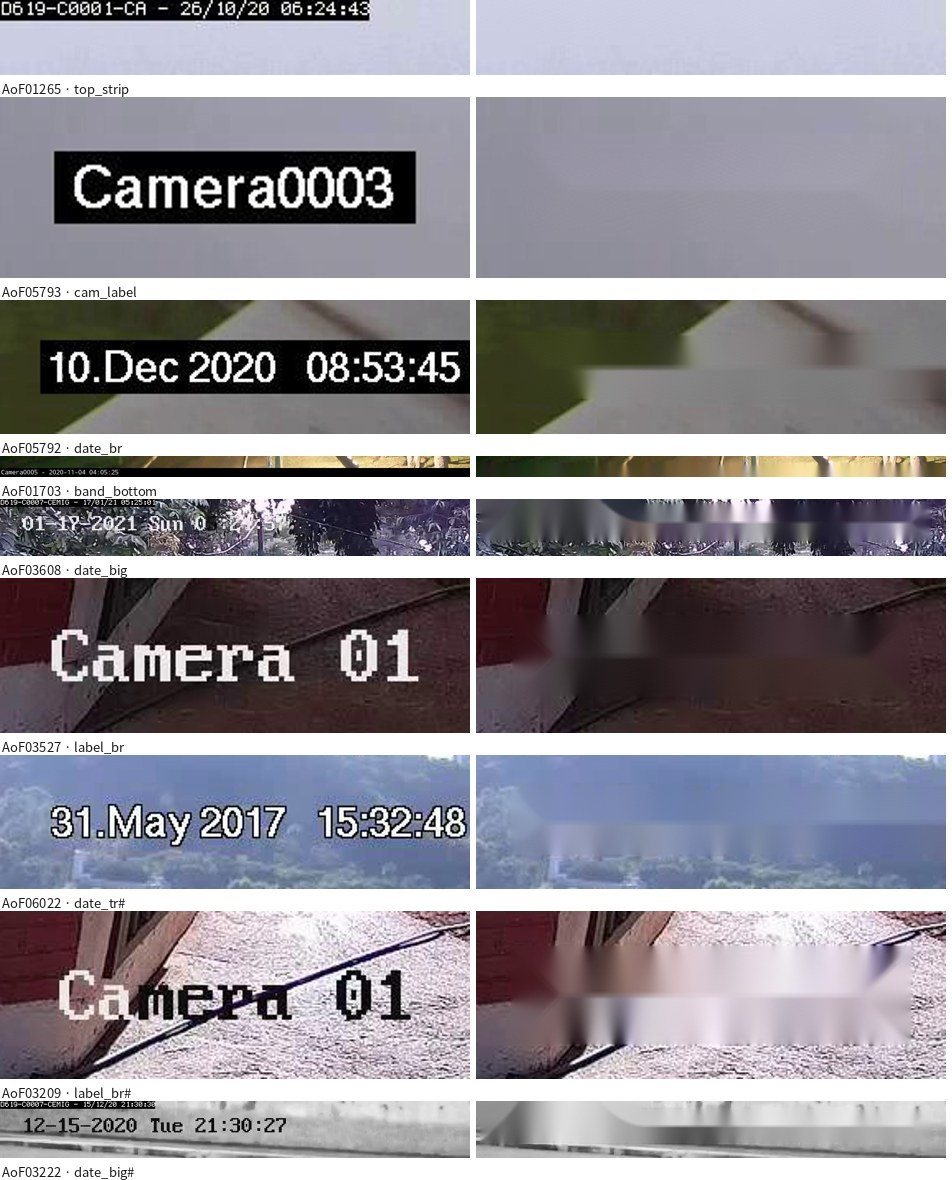

[공개본: 사진가 저작권 표시(워터마크)를 가린 예 1줄(AoF03636)은 그림에서 뺐습니다. 처리 자체는 그대로입니다.]


In [7]:
def zoom_rows(names_kinds, pad=24, tw=470):
    rows = []
    for name, kind in names_kinds:
        r = A[A.name == name].iloc[0]
        rgb = np.asarray(Image.open(f"{ROOT}/{r['path']}").convert('RGB'))
        boxes = json.loads(r['overlays']); out = X.mask_overlays(rgb, boxes)
        n, b = [(n, bb) for n, bb in boxes if base(n) == kind][0]; H, Wd = rgb.shape[:2]
        cx0, cy0, cx1, cy1 = max(0, b[0] - pad), max(0, b[1] - pad), min(Wd, b[2] + pad), min(H, b[3] + pad)
        c1 = Image.fromarray(np.ascontiguousarray(rgb[cy0:cy1, cx0:cx1])); c2 = Image.fromarray(np.ascontiguousarray(out[cy0:cy1, cx0:cx1]))
        sc = min(tw / c1.width, 3.0); c1 = c1.resize((round(c1.width * sc), round(c1.height * sc))); c2 = c2.resize(c1.size)
        rows.append((f'{name} · {n}', c1, c2))
    Ht = sum(c1.height + 22 for _, c1, _ in rows)
    S = Image.new('RGB', (2 * (tw + 6), Ht), '#ffffff'); y = 0; d = ImageDraw.Draw(S)
    for cap, c1, c2 in rows:
        S.paste(c1, (0, y)); S.paste(c2, (tw + 6, y)); d.text((2, y + c1.height + 3), cap, fill='#1a1a19', font=E._font(13)); y += c1.height + 22
    buf = io.BytesIO(); S.save(buf, 'JPEG', quality=88); return buf.getvalue()

# 종류마다 한 장(자동으로 잡은 것이 있으면 자동), 그리고 직접 지정한 예 두 장
pick = []
for k in KINDS:
    auto = A[A.ov.map(lambda v, k=k: any(base(n) == k and not n.endswith('#') for n in v))]
    src = auto if len(auto) else A[A.ov.map(lambda v, k=k: any(base(n) == k for n in v))]
    pick.append((src.sample(1, random_state=3).name.iloc[0], k))
pick += [('AoF03209', 'label_br'), ('AoF03222', 'date_big')]
zb = zoom_rows(pick)
open(f'{FIG}/overlay_zoom.jpg', 'wb').write(zb)
show_jpeg(zb)

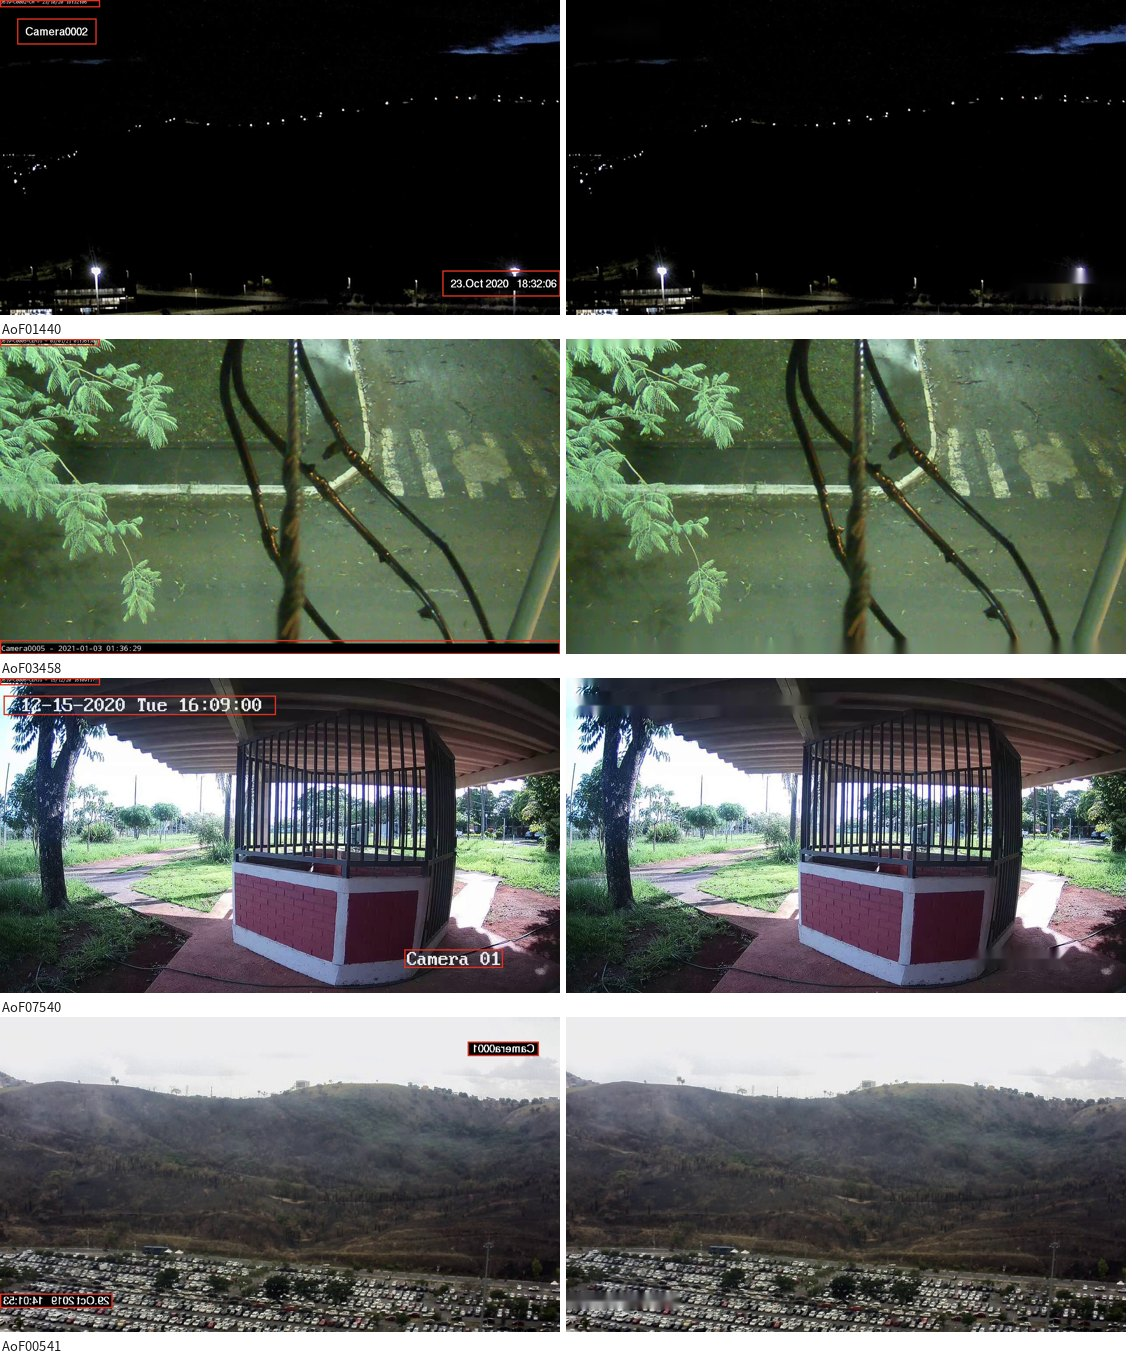

In [8]:
# 전체 화면: 원본(빨간 선 = 가린 자리) | 가린 뒤 — 오른쪽 아래 날짜, 아래 띠, 큰 날짜, 좌우가 뒤집힌 사진
def full_pair(name, tw=560):
    r = D[D.name == name].iloc[0]
    rgb = np.asarray(Image.open(f"{ROOT}/{r['path']}").convert('RGB'))
    boxes = json.loads(r['overlays']); out = X.mask_overlays(rgb, boxes)
    a = Image.fromarray(rgb); dr = ImageDraw.Draw(a)
    for _, b in boxes:
        dr.rectangle(b, outline='#e0301e', width=max(2, rgb.shape[1] // 400))
    s = tw / a.width
    return a.resize((tw, round(a.height * s))), Image.fromarray(out).resize((tw, round(a.height * s)))

names = [A[A.ov.map(lambda v: 'date_br' in v)].sample(1, random_state=11).name.iloc[0],
         A[A.ov.map(lambda v: 'band_bottom' in v)].sample(1, random_state=11).name.iloc[0],
         A[A.ov.map(lambda v: 'date_big' in v)].sample(1, random_state=11).name.iloc[0],
         A[A.ov.map(lambda v: any(n.endswith('~') for n in v))].sample(1, random_state=11).name.iloc[0]]
pairs = [full_pair(n) for n in names]
Ht = sum(p[0].height + 24 for p in pairs)
S = Image.new('RGB', (2 * 566, Ht), '#ffffff'); y = 0; d = ImageDraw.Draw(S)
for n, (p1, p2) in zip(names, pairs):
    S.paste(p1, (0, y)); S.paste(p2, (566, y)); d.text((2, y + p1.height + 3), n, fill='#1a1a19', font=E._font(13)); y += p1.height + 24
buf = io.BytesIO(); S.save(buf, 'JPEG', quality=86); open(f'{FIG}/overlay_full.jpg', 'wb').write(buf.getvalue())
show_jpeg(buf.getvalue())

## 5. 전처리 2 · 크기 맞추기와 전부 처리해 보기

모델은 AI Hub 사진을 1920×972로 학습한다. 다른 출처 사진은 크기·비율이 제각각이라 **비율을 지켜 1920×972 안에 넣고, 남는 곳은 ImageNet 평균색으로 채운다**(정규화하면 0).
불·연기는 모델이 화면에서 차지하는 픽셀 크기로 익히므로, 작은 사진을 키우면 흐려지는 대신 물체 크기가 AI Hub와 비슷해진다. 결과는 출처·원래 크기별로 나눠 본다.
DeepFire(250×250)는 3.9배로 키우게 되어 **원래 크기 그대로 넣는 방식('native')도 함께** 평가한다.

In [9]:
print(inspect.getsource(X.preprocess_external))
print(inspect.getsource(X.fit_geometry))

def preprocess_external(jpeg_bytes, overlay_boxes=(), mode='fit'):
    """다른 출처 사진 → 모델 입력용 PIL 사진. overlay_boxes가 있으면 먼저 메운다.
    mode='fit': 1920×972 캔버스(ImageNet 평균색) 가운데에 비율을 지켜 넣는다. mode='native': 크기를 바꾸지 않는다."""
    rgb = np.asarray(Image.open(io.BytesIO(jpeg_bytes)).convert('RGB'))
    rgb = mask_overlays(rgb, list(overlay_boxes))
    im = Image.fromarray(rgb)
    if mode == 'native':
        return im
    s, ox, oy, nw, nh = fit_geometry(im.width, im.height)
    canvas = Image.new('RGB', (OUT_W, OUT_H), FILL_RGB)
    canvas.paste(im.resize((nw, nh), Image.BICUBIC if s > 1 else Image.LANCZOS), (ox, oy))
    return canvas

def fit_geometry(w, h):
    """'fit': 비율을 지켜 OUT_W×OUT_H 안에 맞출 때의 배율과 왼쪽 위 위치."""
    s = min(OUT_W / w, OUT_H / h)
    nw, nh = round(w * s), round(h * s)
    return s, (OUT_W - nw) // 2, (OUT_H - nh) // 2, nw, nh



In [10]:
ALL = pd.concat([D.assign(dataset='D-Fire'), F[~F.dup_drop].assign(dataset='DeepFire', overlays='[]')], ignore_index=True)
ALL['key'] = ALL.dataset + '/' + ALL.name
geo = ALL.apply(lambda r: X.fit_geometry(r.w, r.h), axis=1, result_type='expand')
ALL['scale'] = geo[0].round(3)
ALL['shape'] = np.where(ALL.w / ALL.h > X.OUT_W / X.OUT_H + 0.01, '가로가 더 김(위아래 여백)', np.where(ALL.w / ALL.h < X.OUT_W / X.OUT_H - 0.01, '세로가 더 김(좌우 여백)', '같음'))
sc = ALL.groupby('src').agg(사진=('key', 'size'), 배율_중앙값=('scale', 'median'), 배율_최소=('scale', 'min'), 배율_최대=('scale', 'max'),
                            키움_1_5배_넘음_pct=('scale', lambda s: pct(s > 1.5)), 줄임_pct=('scale', lambda s: pct(s < 1)))
display(save_tab(sc.round(2), 'scale'))
save_tab(pd.crosstab(ALL.src, ALL['shape']), 'shape')

,사진,배율_중앙값,배율_최소,배율_최대,키움_1_5배_넘음_pct,줄임_pct
src,,,,,,
AoF,8384,1.35,0.45,4.32,3.7,0.1
DeepFire,1896,3.89,3.89,3.89,100.0,0.0
PublicDataset,1336,2.70,0.34,5.01,93.9,2.2
WEB,11807,2.54,0.35,6.48,72.9,3.7


shape,가로가 더 김(위아래 여백),같음,세로가 더 김(좌우 여백)
src,,,
AoF,122,3,8259
DeepFire,0,0,1896
PublicDataset,16,0,1320
WEB,385,50,11372


In [11]:
PS, TH = XL.process_all(ALL[['key', 'path', 'overlays']], 'ext_processed', REBUILD)
assert len(PS) == len(ALL)
PS.index = ALL.index
print(f"처리한 사진 {len(PS):,}장, 오류 {int(PS['error'].notna().sum()) if 'error' in PS else 0}장")
print('처리 후 크기:', PS.groupby(['out_w', 'out_h']).size().to_dict())
print(f"한 장당 처리 시간 중앙값 {1000 * PS.t_prep.median():.0f} ms (가리기 + 1920×972 맞추기 + 원래 크기본)")
ALL = ALL.join(PS.drop(columns=['key']))
ALL['dark'] = ALL.p_bright < 50
ALL['gray_cam'] = (ALL.p_sat < 3) & (ALL.src == 'AoF')
FACTS.update(ext_processed=len(PS), ext_errors=int(PS['error'].notna().sum()) if 'error' in PS else 0,
             ext_out_sizes={f'{int(w)}x{int(h)}': int(c) for (w, h), c in PS.groupby(['out_w', 'out_h']).size().items()})

처리한 사진 23,423장, 오류 0장
처리 후 크기: {(1920, 972): 23423}
한 장당 처리 시간 중앙값 23 ms (가리기 + 1920×972 맞추기 + 원래 크기본)


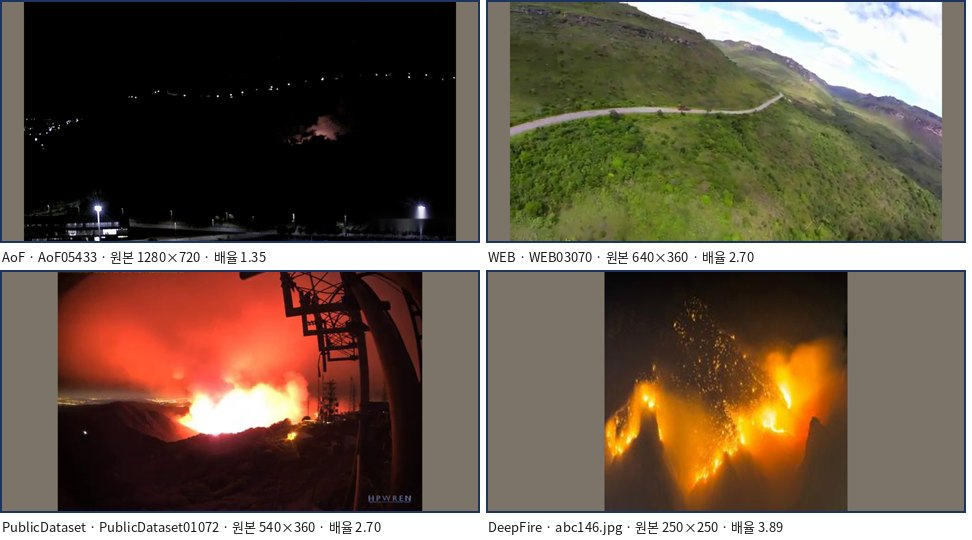

In [12]:
# 처리 예: 출처마다 한 장 — 1920×972로 맞춘 모습 (DeepFire는 원래 크기 250×250도)
ex = [ALL[(ALL.src == 'AoF') & (ALL.overlays != '[]') & (ALL.y == 1)].sample(1, random_state=2),
      ALL[(ALL.src == 'WEB') & (ALL.y == 0)].sample(1, random_state=4),
      ALL[(ALL.src == 'PublicDataset')].sample(1, random_state=2),
      ALL[(ALL.src == 'DeepFire') & (ALL.y == 1)].sample(1, random_state=2)]
tiles = []
for e in ex:
    r = e.iloc[0]
    b = open(f"{ROOT}/{r['path']}", 'rb').read()
    fit = X.preprocess_external(b, json.loads(r['overlays']), 'fit').resize((480, 243))
    d = ImageDraw.Draw(fit); d.rectangle([0, 0, 479, 242], outline='#1d3461', width=2)
    tiles.append((f"{r['src']} · {r['name']} · 원본 {int(r['w'])}×{int(r['h'])} · 배율 {r['scale']:.2f}", fit))
S = Image.new('RGB', (2 * 486, 2 * 270), '#ffffff'); d = ImageDraw.Draw(S)
for i, (cap, t) in enumerate(tiles):
    x, y = (i % 2) * 486, (i // 2) * 270
    S.paste(t, (x, y)); d.text((x + 2, y + 246), cap, fill='#1a1a19', font=E._font(13))
buf = io.BytesIO(); S.save(buf, 'JPEG', quality=86); open(f'{FIG}/fit_examples.jpg', 'wb').write(buf.getvalue())
show_jpeg(buf.getvalue())

## 6. 가공 3 · 거의 같은 사진 묶음과 라벨 의심 음성

### 6.1 거의 같은 사진 묶음

감시 카메라 영상에서 뽑은 사진은 이웃 프레임이 거의 같다. 시험에만 쓰므로 누수는 아니지만, 결과를 읽을 때 사진 수보다 실제 장면이 훨씬 적다는 점을 함께 본다.
EDA 12절과 같은 척도(가린 뒤 32×18 회색 썸네일, 밝기 평균·대비를 맞춘 평균 절대차 < 6 = 거의 같은 사진)로 거의 같은 사진끼리 잇는다.
이은 것을 다시 이으므로, 고정 카메라(AoF)는 하루 동안 조금씩 변하는 프레임이 하나로 이어져 **묶음 하나가 카메라 화면 하나에 가깝다.**

In [13]:
grp, npairs = XL.near_dup_groups(TH)
ALL['dup_group'] = grp
ng = ALL.groupby('dataset').agg(사진=('key', 'size'), 묶음=('dup_group', 'nunique'))
ng['혼자인 사진'] = ALL.groupby('dataset').dup_group.apply(lambda g: int((g.map(g.value_counts()) == 1).sum()))
ng['가장 큰 묶음'] = ALL.groupby('dataset').dup_group.apply(lambda g: int(g.value_counts().max()))
mixed = ALL.groupby('dup_group').y.nunique()
ng['양성·음성이 섞인 묶음'] = ALL.groupby('dataset').dup_group.apply(lambda g: int((mixed.loc[g.unique()] > 1).sum()))
display(save_tab(ng, 'near_dup'))
srcg = ALL[ALL.dataset == 'D-Fire'].groupby('src').agg(사진=('key', 'size'), 묶음=('dup_group', 'nunique'))
display(save_tab(srcg, 'near_dup_src'))
cross_ds = ALL.groupby('dup_group').dataset.nunique()
print('D-Fire와 DeepFire가 섞인 묶음:', int((cross_ds > 1).sum()), '— 눈으로 보니 서로 다른 사진(밝은 하늘 아래 어두운 산의 단순한 구도가 썸네일에서 겹침)')
FACTS.update(dfire_groups=int(ng.loc['D-Fire', '묶음']), deepfire_groups=int(ng.loc['DeepFire', '묶음']),
             aof_groups=int(srcg.loc['AoF', '묶음']), cross_ds_groups=int((cross_ds > 1).sum()))

,사진,묶음,혼자인 사진,가장 큰 묶음,양성·음성이 섞인 묶음
dataset,,,,,
D-Fire,21527,10661,9778,1208,59
DeepFire,1896,1891,1886,2,1


,사진,묶음
src,,
AoF,8384,566
PublicDataset,1336,651
WEB,11807,9479


D-Fire와 DeepFire가 섞인 묶음: 1 — 눈으로 보니 서로 다른 사진(밝은 하늘 아래 어두운 산의 단순한 구도가 썸네일에서 겹침)


양성·음성이 섞인 묶음은 같은 카메라 화면에서 연기가 있는 프레임과 없는 프레임이 이어진 것이다(라벨 오류가 아니다).
썸네일이 작아 구도가 단순한 사진은 다른 사진끼리도 이어질 수 있어, 묶음 수는 대략의 값이다.

### 6.2 라벨 의심 음성: 불·연기가 보이는 '음성'

D-Fire 음성 9,838장 전부를 SigLIP 제로샷 모델로 '무엇처럼 보이는지' 태그했고(`tag_lookalike_clip.py`), '산불'로 태그된 음성 847장은 **모두 눈으로 봤다.**
대부분 안개·연무·구름·렌즈 얼룩(카메라 앞 벌레·물방울)이라 음성이 맞았다. 다음은 그대로 음성으로 두기 어려운 사진이다.

| 구분 | 사진 | 처리 |
|---|---|---|
| 불·연기가 보임 (라벨 오류로 판단) | AoF03261~03265, AoF07553: 2020-12-26 14:59~15:00 능선 위 연기 기둥 / WEB02457: 숲 뒤 주황 불빛(산불) | 시험에서 뺌 |
| 판별 불확실 | WEB01560~01572, WEB09864~09871: 해가 흐린 원반으로 보이는 짙은 분홍빛 연무 하늘(먼 산불 연기 연무일 수 있음) / WEB10273: 지평선의 폭풍 구름과 연기 같은 띠 | 시험 주 결과에서 빼고 따로 본다 |
| 음성 그대로 | WEB00350~00366, WEB09545~09553: 산꼭대기를 덮은 구름의 시간 경과 영상(역광으로 짙은 갈색) | 구름 음성 — 가설에 꼭 필요한 사례 |

같은 영상의 이웃 프레임은 이름 번호를 따라 직접 확인해 목록에 넣었다(6.1 묶음으로 넓히면 같은 카메라 화면 전체가 딸려 와서 쓰지 않는다).
눈으로 본 것은 '산불' 태그 847장과 그 이웃 프레임뿐이라, 다른 음성에도 표시되지 않은 연기가 있을 수 있다.

사진
label_issue  src    
ambiguous    WEB  22
fire_visible AoF   6
             WEB   1

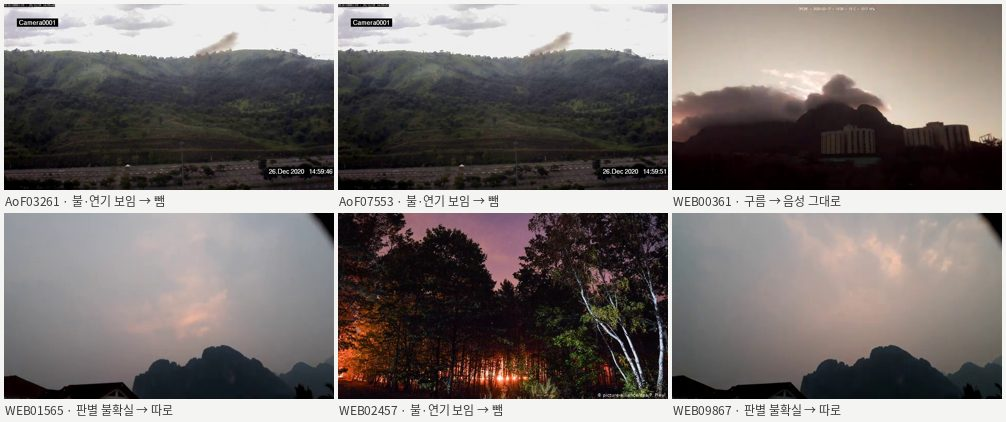

In [14]:
FIRE_VISIBLE = ['AoF03261', 'AoF03262', 'AoF03263', 'AoF03264', 'AoF03265', 'AoF07553', 'WEB02457']
AMBIGUOUS = [f'WEB{n:05d}' for n in list(range(1560, 1573)) + list(range(9864, 9872)) + [10273]]
ALL['label_issue'] = ''
dfn = (ALL.dataset == 'D-Fire') & (ALL.y == 0)
ALL.loc[dfn & ALL.name.isin(FIRE_VISIBLE), 'label_issue'] = 'fire_visible'
ALL.loc[dfn & ALL.name.isin(AMBIGUOUS), 'label_issue'] = 'ambiguous'
assert (ALL.label_issue == 'fire_visible').sum() == len(FIRE_VISIBLE) and (ALL.label_issue == 'ambiguous').sum() == len(AMBIGUOUS)
iss = ALL[ALL.label_issue != ''].groupby(['label_issue', 'src']).size().rename('사진').to_frame()
display(save_tab(iss, 'label_issue'))
rows = ALL[ALL.name.isin(['AoF03261', 'AoF07553', 'WEB02457', 'WEB01565', 'WEB09867', 'WEB00361'])].sort_values('name')
note = {'fire_visible': '불·연기 보임 → 뺌', 'ambiguous': '판별 불확실 → 따로', '': '구름 → 음성 그대로'}
tiles = [dict(img=Image.open(f"{ROOT}/{r['path']}").convert('RGB'), caption=f"{r['name']} · {note[r['label_issue']]}")
         for _, r in rows.iterrows()]
gb = E.grid(tiles, cols=3, tw=330)
open(f'{FIG}/label_issue.jpg', 'wb').write(gb); show_jpeg(gb)
FACTS.update(issue_fire=int((ALL.label_issue == 'fire_visible').sum()), issue_amb=int((ALL.label_issue == 'ambiguous').sum()))

## 7. 결과 확인

### 7.1 최종 시험 구성

In [15]:
ALL['use'] = ALL.label_issue == ''
fin = pd.crosstab([ALL.dataset, ALL.src], [ALL.y.map({1: '양성', 0: '음성'}), ALL['sub']])
fin['합계'] = fin.sum(axis=1)
fin.loc[('합계', ''), :] = fin.sum()
use = pd.crosstab([ALL.dataset, ALL.label_issue.replace('', '시험에 씀')], ALL.y.map({1: '양성', 0: '음성'}))
display(save_tab(fin.astype(int), 'final_by_src'))
display(save_tab(use, 'final_use'))
FACTS.update(dfire_use=int((ALL.use & (ALL.dataset == 'D-Fire')).sum()), deepfire_use=int((ALL.use & (ALL.dataset == 'DeepFire')).sum()),
             dfire_pos=int((ALL.use & (ALL.dataset == 'D-Fire') & (ALL.y == 1)).sum()), dfire_neg=int((ALL.use & (ALL.dataset == 'D-Fire') & (ALL.y == 0)).sum()),
             deepfire_pos=int((ALL.use & (ALL.dataset == 'DeepFire') & (ALL.y == 1)).sum()), deepfire_neg=int((ALL.use & (ALL.dataset == 'DeepFire') & (ALL.y == 0)).sum()))

y                         양성           음성     합계
sub                       불꽃    연기     정상       
dataset  src                                    
D-Fire   AoF            1329  2041   5014   8384
         PublicDataset   270   900    166   1336
         WEB            4223  2926   4658  11807
DeepFire DeepFire        948     0    948   1896
합계                      6770  5867  10786  23423

y                         양성    음성
dataset  label_issue              
D-Fire   ambiguous         0    22
         fire_visible      0     7
         시험에 씀         11689  9809
DeepFire 시험에 씀           948   948

### 7.2 불·연기 크기: AI Hub와 비교

모델은 불·연기를 화면에서 차지하는 픽셀 크기로 익힌다. 사진마다 가장 큰 불·연기 박스의 짧은 변을 **모델에 들어가는 크기**(AI Hub 1920×972, D-Fire는 1920×972에 맞춘 뒤)로 잰다.
DeepFire는 박스가 없다(불이 화면을 거의 채운 사진이 대부분).

,사진,10%,중앙값,90%,16px 미만 %
AI Hub 화염,86702.0,15.8,35.7,75.4,10.4
AI Hub 연기,208783.0,67.3,255.5,476.4,0.5
D-Fire 화염,5822.0,37.8,114.8,326.7,0.5
D-Fire 연기,10525.0,62.1,380.7,720.9,0.0


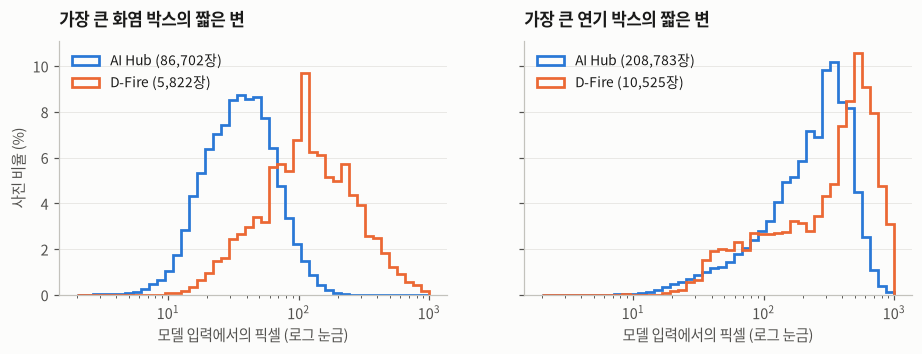

In [16]:
B = DB[DB.valid].merge(ALL.loc[ALL.dataset == 'D-Fire', ['name', 'w', 'h', 'scale']], on='name')
B['short_fit'] = np.minimum(B.bw * B.w, B.bh * B.h) * B.scale
bmax = B.groupby(['name', 'cls']).short_fit.max().unstack()
ALL = ALL.merge(bmax.rename(columns={'fire': 'fire_short_fit', 'smoke': 'smoke_short_fit'}), left_on='name', right_index=True, how='left')
ALL.loc[ALL.dataset != 'D-Fire', ['fire_short_fit', 'smoke_short_fit']] = np.nan
man = W.load_manifest()
S_ = {('AI Hub', '화염'): man.fire_short.dropna(), ('AI Hub', '연기'): man.smoke_short.dropna(),
      ('D-Fire', '화염'): ALL.loc[ALL.use, 'fire_short_fit'].dropna(), ('D-Fire', '연기'): ALL.loc[ALL.use, 'smoke_short_fit'].dropna()}
bs = pd.DataFrame({f'{a} {b}': {'사진': len(v), '10%': v.quantile(.1), '중앙값': v.median(), '90%': v.quantile(.9), '16px 미만 %': pct(v < 16)} for (a, b), v in S_.items()}).T.round(1)
display(save_tab(bs, 'box_size'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), sharey=True)
bins = np.logspace(np.log10(2), np.log10(1000), 45)
for ax, kind in zip(axes, ['화염', '연기']):
    for ds in ['AI Hub', 'D-Fire']:
        v = S_[(ds, kind)]
        ax.hist(v, bins=bins, histtype='step', weights=np.full(len(v), 100 / len(v)), color=DS_COLOR[ds], linewidth=1.8, label=f'{ds} ({len(v):,}장)')
    ax.set_xscale('log'); ax.set_title(f'가장 큰 {kind} 박스의 짧은 변'); ax.set_xlabel('모델 입력에서의 픽셀 (로그 눈금)'); ax.grid(axis='y')
axes[0].set_ylabel('사진 비율 (%)'); axes[0].legend(loc='upper left'); axes[1].legend(loc='upper left')
fig.savefig(f'{FIG}/box_size.png', dpi=200, bbox_inches='tight'); plt.show()

### 7.3 밝기와 밤 사진, 적외선(흑백) 화면

AI Hub에는 밤 음성이 없어 '어두우면 양성' 지름길을 배울 수 있다(전처리 노트북 7.4). D-Fire에는 **어두운 음성**(대부분 감시 카메라 밤 화면, 그 밖에 도시 야경·번개)이 있어 이 지름길을 시험할 수 있다.
어두운 사진 = 가린 뒤 사진 내용(회색 여백 제외)의 밝기 < 50(AI Hub와 같은 기준).

In [17]:
u = ALL[ALL.use]
dk = u.groupby(['dataset', 'src', u.y.map({1: '양성', 0: '음성'})]).agg(사진=('key', 'size'), 어두운_사진=('dark', 'sum'))
dk['어두운 비율 %'] = (100 * dk.어두운_사진 / dk.사진).round(1)
display(save_tab(dk, 'dark'))
gc = u[u.gray_cam].groupby(u.y.map({1: '양성', 0: '음성'})).size()
print('감시 카메라 적외선(흑백) 화면:', gc.to_dict())
FACTS.update(dfire_dark_neg=int(((u.dataset == 'D-Fire') & (u.y == 0) & u.dark).sum()), dfire_dark_pos=int(((u.dataset == 'D-Fire') & (u.y == 1) & u.dark).sum()),
             gray_cam=int(u.gray_cam.sum()))

사진  어두운_사진  어두운 비율 %
dataset  src           y                         
D-Fire   AoF           양성  3370    1316      39.1
                       음성  5008     395       7.9
         PublicDataset 양성  1170     122      10.4
                       음성   166      11       6.6
         WEB           양성  7149    1061      14.8
                       음성  4635     490      10.6
DeepFire DeepFire      양성   948     147      15.5
                       음성   948      18       1.9

감시 카메라 적외선(흑백) 화면: {'양성': 3, '음성': 58}


### 7.4 헷갈리는 음성: 자동 태그

음성 사진이 무엇처럼 보이는지 SigLIP 제로샷 태그(종류별 문장과 사진의 유사도가 가장 큰 종류)로 묶는다. 사람 라벨이 아니라 모델 추정이므로 종류별로 표본을 눈으로 확인했다
(구름·안개·노을·밤 불빛은 대부분 맞고, 번개는 실제 번개와 폭풍 하늘이 섞여 있다).

In [18]:
tags = pd.read_csv(f'{ROOT}/report/lookalike/clip_tags_full.csv.gz', usecols=['key', 'dataset', 'kind', 'tag'], low_memory=False)
tags = tags[tags.dataset.isin(['D-Fire', 'DeepFire']) & (tags.kind == 'neg')]
tags['path'] = tags.key.map(lambda p: os.path.relpath(p, ROOT))
ALL = ALL.merge(tags[['path', 'tag']], on='path', how='left')
tg = pd.crosstab(ALL.loc[ALL.use & (ALL.y == 0), 'tag'], ALL.loc[ALL.use & (ALL.y == 0), 'dataset'])
tg = tg.loc[tg.sum(axis=1).sort_values(ascending=False).index]
display(save_tab(tg, 'neg_tags'))

dataset,D-Fire,DeepFire
tag,,
일반 풍경,4783,862
노을·해,1191,14
밤 불빛,1074,0
산불,833,4
구름,689,2
안개,668,23
번개,450,0
굴뚝·공장 연기,59,1
단풍·마른 풀,7,41


## 8. 시험 묶음

다른 출처 시험 결과를 나눠 볼 묶음을 목록 열로 바로 고를 수 있는 조건식으로 저장한다(`prep/external_test_groups.csv`). 음성 묶음은 오경보율, 양성 묶음은 Recall을 낸다.

In [19]:
G = [('D-Fire 전체', "dataset == 'D-Fire'"), ('D-Fire 음성', "dataset == 'D-Fire' and y == 0"), ('D-Fire 양성', "dataset == 'D-Fire' and y == 1"),
     ('감시 카메라(AoF) 음성', "src == 'AoF' and y == 0"), ('감시 카메라(AoF) 양성', "src == 'AoF' and y == 1"),
     ('인터넷(WEB) 음성', "src == 'WEB' and y == 0"), ('인터넷(WEB) 양성', "src == 'WEB' and y == 1"),
     ('공개 데이터 음성', "src == 'PublicDataset' and y == 0"),
     ('D-Fire 밤(어두운) 음성', "dataset == 'D-Fire' and y == 0 and dark"), ('D-Fire 밤(어두운) 양성', "dataset == 'D-Fire' and y == 1 and dark"),
     ('적외선(흑백) 화면 음성', 'gray_cam and y == 0'),
     ('음성 · 구름', "dataset == 'D-Fire' and y == 0 and tag == '구름'"), ('음성 · 안개', "dataset == 'D-Fire' and y == 0 and tag == '안개'"),
     ('음성 · 노을·해', "dataset == 'D-Fire' and y == 0 and tag == '노을·해'"), ('음성 · 밤 불빛', "dataset == 'D-Fire' and y == 0 and tag == '밤 불빛'"),
     ('음성 · 번개', "dataset == 'D-Fire' and y == 0 and tag == '번개'"), ('음성 · 굴뚝·공장 연기', "dataset == 'D-Fire' and y == 0 and tag == '굴뚝·공장 연기'"),
     ('음성 · 산불처럼 보임(안개·렌즈 얼룩 등)', "dataset == 'D-Fire' and y == 0 and tag == '산불'"),
     ('양성 · 불꽃', "dataset == 'D-Fire' and y == 1 and sub == '불꽃'"), ('양성 · 연기만', "dataset == 'D-Fire' and y == 1 and sub == '연기'"),
     ('양성 · 화염 짧은 변 <16px', "dataset == 'D-Fire' and y == 1 and fire_short_fit < 16"),
     ('DeepFire 전체', "dataset == 'DeepFire'"), ('DeepFire 음성', "dataset == 'DeepFire' and y == 0"), ('DeepFire 양성(불)', "dataset == 'DeepFire' and y == 1"),
     ('DeepFire 어두운 양성', "dataset == 'DeepFire' and y == 1 and dark")]
G += [('판별 불확실(연무 하늘) — 주 결과와 따로', "label_issue == 'ambiguous'")]
rows = []
for name, q in G:
    q = q if 'label_issue' in q else f'use and {q}'
    g = ALL.query(q, engine='python')
    rows.append((name, q, len(g), g.dup_group.nunique()))
groups = pd.DataFrame(rows, columns=['묶음', '조건 (pandas query)', '사진', '거의 같은 사진 묶음'])
groups.to_csv(f'{W.PREP}/external_test_groups.csv', index=False)
save_tab(groups, 'test_groups')
groups.drop(columns='조건 (pandas query)')

,묶음,사진,거의 같은 사진 묶음
0,D-Fire 전체,21498,10659
1,D-Fire 음성,9809,3669
2,D-Fire 양성,11689,7048
3,감시 카메라(AoF) 음성,5008,303
4,감시 카메라(AoF) 양성,3370,288
5,인터넷(WEB) 음성,4635,3204
6,인터넷(WEB) 양성,7149,6286
7,공개 데이터 음성,166,166
8,D-Fire 밤(어두운) 음성,896,387
9,D-Fire 밤(어두운) 양성,2499,1055


## 9. 산출물

In [20]:
COLS = ['dataset', 'src', 'name', 'path', 'orig_split', 'y', 'sub', 'use', 'label_issue', 'w', 'h', 'scale', 'overlays',
        'n_fire', 'n_smoke', 'n_bad_box', 'fire_short_fit', 'smoke_short_fit', 'p_bright', 'dark', 'gray_cam', 'tag', 'dup_group', 'md5']
for c in ('n_fire', 'n_smoke', 'n_bad_box'):
    ALL[c] = ALL[c].fillna(0).astype(int)
ext = ALL[COLS].sort_values(['dataset', 'src', 'name']).reset_index(drop=True)
ext.to_csv(f'{W.PREP}/external_manifest.csv.gz', index=False)
DB.merge(ALL.loc[ALL.dataset == 'D-Fire', ['name', 'path', 'w', 'h']], on='name').to_csv(f'{W.PREP}/external_boxes.csv.gz', index=False)
json.dump(FACTS, open(f'{TAB}/facts.json', 'w'), ensure_ascii=False, indent=1, default=str)
files = ['external_manifest.csv.gz', 'external_boxes.csv.gz', 'external_test_groups.csv']
display(pd.DataFrame([(f, f'{os.path.getsize(f"{W.PREP}/{f}") / 1e6:.2f} MB') for f in files], columns=['prep/ 파일', '크기']))
print(f"시험에 쓰는 사진: D-Fire {FACTS['dfire_use']:,}장 (양성 {FACTS['dfire_pos']:,} · 음성 {FACTS['dfire_neg']:,}), "
      f"DeepFire {FACTS['deepfire_use']:,}장 (양성 {FACTS['deepfire_pos']:,} · 음성 {FACTS['deepfire_neg']:,})")

,prep/ 파일,크기
0,external_manifest.csv.gz,1.07 MB
1,external_boxes.csv.gz,0.59 MB
2,external_test_groups.csv,0.00 MB


시험에 쓰는 사진: D-Fire 21,498장 (양성 11,689 · 음성 9,809), DeepFire 1,896장 (양성 948 · 음성 948)


| 파일 | 내용 |
|---|---|
| `prep/external_manifest.csv.gz` | 다른 출처 시험 사진 한 장에 한 줄: 데이터·출처, 원본 경로, 라벨(y, sub), 시험에 쓰는지(use)·라벨 의심(label_issue), 원본 크기·배율, 가린 글자 자리(overlays, JSON), 박스 크기, 밝기·밤, 적외선, 자동 태그, 거의 같은 사진 묶음 |
| `prep/external_boxes.csv.gz` | D-Fire 박스 (YOLO 비율 좌표, 크기 0 박스 표시) |
| `prep/external_test_groups.csv` | 시험 묶음과 고르는 조건식 |
| `../external_data.py` | `overlay_boxes()`(= `find_overlays()` 자동 + `MANUAL_OVERLAYS` 직접 지정), `mask_overlays()`, `preprocess_external()` — 평가 코드가 그대로 가져다 쓴다 |

평가 때는 `preprocess_external(원본 바이트, json.loads(overlays), mode)`로 사진을 만든다. mode는 'fit'(기본, 1920×972)과 DeepFire용 'native'(250×250).